# Find relevant pages

A fund's annual report runs 59 pages, and you want three things from it: its holdings, its financial highlights and its board of trustees. Each is in its own part of the report, between pages of narrative, statements and notes. Read every page once, ask TypeLLM for each field whether the page holds information for it, and send each field only its pages.

The question is the same for every field and every document.

In [1]:
%pip install -q "typellm>=0.7.2" pymupdf huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Paste your API key here.
TYPELLM_API_KEY = ""  # https://typellm.ai/dashboard/keys

In [3]:
import json

import pymupdf
from huggingface_hub import hf_hub_download
from typellm import TypeLLMClient

client = TypeLLMClient(api_key=TYPELLM_API_KEY, timeout=90)

# The report and its ground truth, from the ExtractBench dataset.
NAME = "real_credit_strategies_full"
pdf = hf_hub_download("llamaindex/ExtractBench", f"docs/long/{NAME}.pdf", repo_type="dataset")
rows = [json.loads(line) for line in open(hf_hub_download("llamaindex/ExtractBench", "long.jsonl", repo_type="dataset"))]
truth = json.loads(next(r for r in rows if r["pdf"].endswith(f"/{NAME}.pdf"))["expected_output"])

doc = pymupdf.open(pdf)
print(f"{doc.page_count} pages")

59 pages


## Describe the data

One field for each thing you want, with a sentence on what it holds. Keep what belongs together in one field: a holding's name and its value, or a trustee's name and position. Asked apart, each question judges a page on its own, so a page holding part of a record can score low on both and be left out.

In [4]:
FIELDS = {
    "holdings": "Every holding in the schedule of investments: its security name and value.",
    "financial_highlights": "For each share class, its net asset value, total return and expense ratio for the latest year.",
    "trustees": "Every trustee on the fund's board: name, year of birth and position.",
}

## Ask each page

Send each page's image and its text, with the fields. Ask one yes/no question per field, and keep the probability of yes. One call answers all three.

If you already have a JSON Schema for your extractor, you can put it in the context as it is, and ask the question for each of its top-level fields.

In [5]:
from concurrent.futures import ThreadPoolExecutor


def ask(page):
    context = ("Data will be extracted from a document into these fields:\n"
               + "\n".join(f"- {f}: {what}" for f, what in FIELDS.items())
               + "\n\nBelow is one page of the document: its image is attached, and its text follows.\n\n"
               + (page.get_text().strip() or "(no text layer)"))
    questions = {f: {"type": "boolean", "return_probabilities": True,
                     "instructions": f'Does this page contain information for the field "{f}"?'} for f in FIELDS}
    image = page.get_pixmap(dpi=120).tobytes("png")
    result = client.generate(context=context, images=[image], questions=questions).result
    return {f: result[f]["probabilities"][True] for f in FIELDS}


with ThreadPoolExecutor(4) as pool:
    probs = list(pool.map(ask, doc))
for number in (4, 12, 35, 40, 54):
    print(f"page {number}: " + ", ".join(f"{f} {probs[number - 1][f]:.2f}" for f in FIELDS))

page 4: holdings 0.00, financial_highlights 0.08, trustees 0.00
page 12: holdings 1.00, financial_highlights 0.00, trustees 0.00
page 35: holdings 0.00, financial_highlights 1.00, trustees 0.00
page 40: holdings 0.00, financial_highlights 0.00, trustees 0.00
page 54: holdings 0.00, financial_highlights 0.00, trustees 1.00


Each call reads about 2,900 input tokens, mostly the page's image and text, and the answers are free: $0.00014 a page at $0.05 per million input tokens, $0.0085 for the whole report.

## Pick the pages

Each field takes every page where yes is at least 0.3.

In [6]:
picked = {f: [n for n in range(1, doc.page_count + 1) if probs[n - 1][f] >= 0.3] for f in FIELDS}
for f in FIELDS:
    print(f"{f}: {picked[f]}")

send = sorted(set().union(*picked.values()))
print(f"\nsend {len(send)} of {doc.page_count} pages, each to the fields it holds")

holdings: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]
financial_highlights: [33, 34, 35, 36, 37]
trustees: [54, 55]

send 26 of 59 pages, each to the fields it holds


## Check

The holdings' pages come from the dataset's ground truth, whose schedule of investments starts on the report's page 8. The financial highlights are the pages that open with a share class's net asset value at the beginning of the year, and the trustees are the pages with the board's table.

In [7]:
true_pages = {
    "holdings": sorted({h["source_page"] + 7 for h in truth["holdings"]}),
    "financial_highlights": [n for n in range(1, doc.page_count + 1) if "Net asset value, beginning of" in doc[n - 1].get_text()],
    "trustees": [n for n in range(1, doc.page_count + 1) if "Year of Birth" in doc[n - 1].get_text()],
}
for f in FIELDS:
    extra, missed = sorted(set(picked[f]) - set(true_pages[f])), sorted(set(true_pages[f]) - set(picked[f]))
    print(f"{f}: {len(true_pages[f])} pages, picked but not there {extra}, there but not picked {missed}")

holdings: 19 pages, picked but not there [], there but not picked []
financial_highlights: 5 pages, picked but not there [], there but not picked []
trustees: 2 pages, picked but not there [], there but not picked []


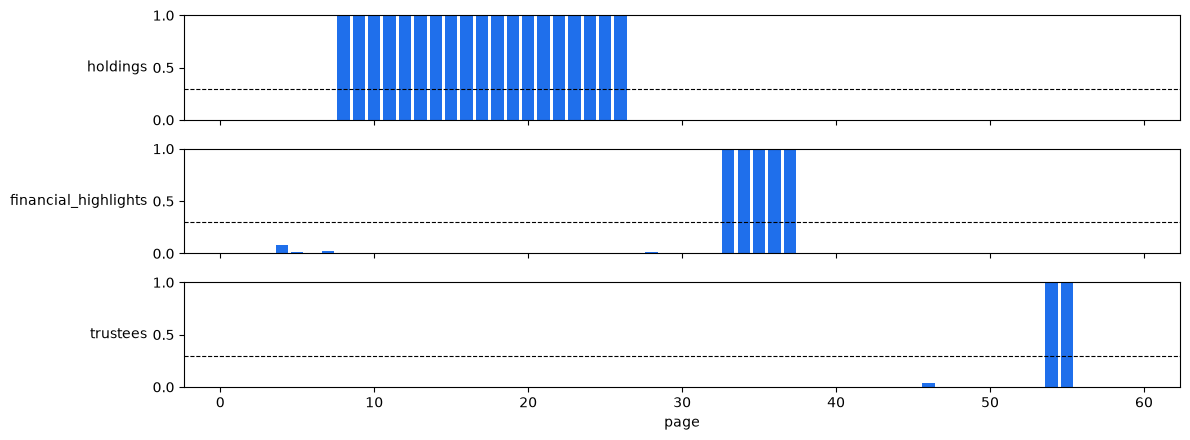

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(FIELDS), 1, figsize=(12, 4.5), sharex=True)
for ax, f in zip(axes, FIELDS):
    ax.bar(range(1, doc.page_count + 1), [p[f] for p in probs], color="#1f6feb")
    ax.axhline(0.3, color="black", lw=0.8, ls="--")
    ax.set_ylim(0, 1)
    ax.set_ylabel(f, rotation=0, ha="right", va="center")
axes[-1].set_xlabel("page")
plt.tight_layout()
plt.show()